In [1]:
# Cell 1: Import necessary libraries
import os
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
from torch.cuda.amp import GradScaler, autocast
from tqdm import tqdm
import gc

In [2]:
# Cell 2: Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Cell 3: Unzip the images zip file from Drive to Colab
# Assume the zip is at /content/drive/MyDrive/book_images_small.zip
# Unzip to /content/book_images_small
!unzip /content/drive/MyDrive/book_images_small.zip -d /content/book_images_small
img_dir = '/content/book_images_small/book_images_small'  # Adjust if unzip creates subfolder, e.g., '/content/book_images_small/book_images_small' if nested

Streaming output truncated to the last 5000 lines.
  inflating: /content/book_images_small/book_images_small/61sADBuaZkL.jpg  
  inflating: /content/book_images_small/book_images_small/61SAe9m7BhL.jpg  
  inflating: /content/book_images_small/book_images_small/61sagbMTNOL.jpg  
  inflating: /content/book_images_small/book_images_small/61sakGWRvOL.jpg  
  inflating: /content/book_images_small/book_images_small/61salSdLN8L.jpg  
  inflating: /content/book_images_small/book_images_small/61samjLiRCL.jpg  
  inflating: /content/book_images_small/book_images_small/61SAmvPU3RL.jpg  
  inflating: /content/book_images_small/book_images_small/61SAN12re0L.jpg  
  inflating: /content/book_images_small/book_images_small/61saNe0ip3L.jpg  
  inflating: /content/book_images_small/book_images_small/61SAnFNvvXL.jpg  
  inflating: /content/book_images_small/book_images_small/61saorcNFJL.jpg  
  inflating: /content/book_images_small/book_images_small/61SapUJI3zL.jpg  
  inflating: /content/book_images_sma

In [4]:
# Cell 4: Load CSV and preprocess
# Assume CSV is at /content/drive/MyDrive/book_list.csv
csv_path = '/content/drive/MyDrive/book_list.csv'
df = pd.read_csv(csv_path, encoding='latin-1')

# Extract filename from IMAGE URL
df['filename'] = df['IMAGE URL'].apply(lambda x: x.split('/')[-1])

# Get list of available images
available_images = set(os.listdir(img_dir))

# Filter rows where image exists
df = df[df['filename'].isin(available_images)].reset_index(drop=True)

# Get number of classes (assuming CATEGORY ID is the label, starting from 0)
num_classes = df['CATEGORY ID'].nunique()
print(f"Number of classes: {num_classes}")
print(f"Filtered dataset size: {len(df)}")

Number of classes: 32
Filtered dataset size: 207552


In [5]:
# Cell 5: Split the dataset
# 50% train, 20% val, 30% test (from original)
train_df, temp_df = train_test_split(df, test_size=0.5, stratify=df['CATEGORY ID'], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.3, stratify=temp_df['CATEGORY ID'], random_state=42)  # 0.4 of 50% = 20% of original

print(f"Train size: {len(train_df)}")
print(f"Val size: {len(val_df)}")
print(f"Test size: {len(test_df)}")

Train size: 103776
Val size: 72643
Test size: 31133


In [6]:
# Cell 6: Define custom Dataset class
class BookDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, row['filename'])
        image = Image.open(img_path).convert('RGB')
        label = row['CATEGORY ID']  # Assuming CATEGORY ID is integer label starting from 0
        if self.transform:
            image = self.transform(image)
        return image, label

In [7]:
# Cell 7: Define transforms
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [8]:
# Cell 8: Create datasets and dataloaders
# Use batch size 128 to utilize GPU memory (adjust if OOM, e.g., to 64 for larger models)
batch_size = 128
num_workers = 4  # For faster data loading

train_ds = BookDataset(train_df, img_dir, train_transform)
val_ds = BookDataset(val_df, img_dir, val_transform)
test_ds = BookDataset(test_df, img_dir, val_transform)

train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=True)
val_dl = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
test_dl = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [9]:
# Cell 9: Define training and evaluation functions
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def train_epoch(model, dataloader, criterion, optimizer, scaler):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    for inputs, labels in tqdm(dataloader):
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        with autocast():
            outputs = model(inputs)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
    return total_loss / len(dataloader), correct / total

def evaluate(model, dataloader, criterion):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in tqdm(dataloader):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
    return total_loss / len(dataloader), correct / total

In [10]:
# Cell: Train ResNet model with history tracking
from torchvision.models import resnet101, ResNet101_Weights

model_res = resnet101(weights=ResNet101_Weights.DEFAULT)
num_ftrs = model_res.fc.in_features
model_res.fc = nn.Linear(num_ftrs, num_classes)
model_res.to(device)

criterion = nn.CrossEntropyLoss()
optimizer_res = optim.AdamW(model_res.parameters(), lr=1e-3)
scaler_res = GradScaler()
scheduler_res = optim.lr_scheduler.ReduceLROnPlateau(optimizer_res, mode='min', factor=0.1, patience=3)

epochs = 15
best_acc = 0

# Initialize history
history_res = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

print("Starting ResNet training...")
for epoch in range(epochs):
    train_loss, train_acc = train_epoch(model_res, train_dl, criterion, optimizer_res, scaler_res)
    val_loss, val_acc = evaluate(model_res, val_dl, criterion)
    scheduler_res.step(val_loss)

    # Store metrics
    history_res['train_loss'].append(train_loss)
    history_res['train_acc'].append(train_acc)
    history_res['val_loss'].append(val_loss)
    history_res['val_acc'].append(val_acc)

    print(f"Epoch {epoch+1}: Train Loss {train_loss:.4f}, Acc {train_acc:.4f} | Val Loss {val_loss:.4f}, Acc {val_acc:.4f}")

    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model_res.state_dict(), 'resnet_best.pth')
        print(f"New best model saved with Val Acc: {best_acc:.4f}")

    gc.collect()
    torch.cuda.empty_cache()

# Final evaluation
test_loss, test_acc = evaluate(model_res, test_dl, criterion)
print(f"Final ResNet Test Acc: {test_acc:.4f}")

# Save history for visualization
import pickle
with open('resnet_history.pkl', 'wb') as f:
    pickle.dump(history_res, f)
print("Training history saved to 'resnet_history.pkl'")

Downloading: "https://download.pytorch.org/models/resnet101-cd907fc2.pth" to /root/.cache/torch/hub/checkpoints/resnet101-cd907fc2.pth


100%|██████████| 171M/171M [00:10<00:00, 16.4MB/s]
/tmp/ipython-input-3127116340.py:11: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler_res = GradScaler()


Starting ResNet training...


  0%|          | 0/811 [00:00<?, ?it/s]/tmp/ipython-input-3720486319.py:12: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
100%|██████████| 568/568 [05:42<00:00,  1.66it/s]


Epoch 1: Train Loss 2.8215, Acc 0.2175 | Val Loss 2.6926, Acc 0.2529
New best model saved with Val Acc: 0.2529


100%|██████████| 568/568 [05:41<00:00,  1.66it/s]


... (25 outputs left out)

100%|██████████| 568/568 [05:38<00:00,  1.68it/s]


Epoch 15: Train Loss 2.0093, Acc 0.4195 | Val Loss 2.4177, Acc 0.3537
New best model saved with Val Acc: 0.3537


100%|██████████| 244/244 [02:27<00:00,  1.66it/s]

Final ResNet Test Acc: 0.3512
Training history saved to 'resnet_history.pkl'


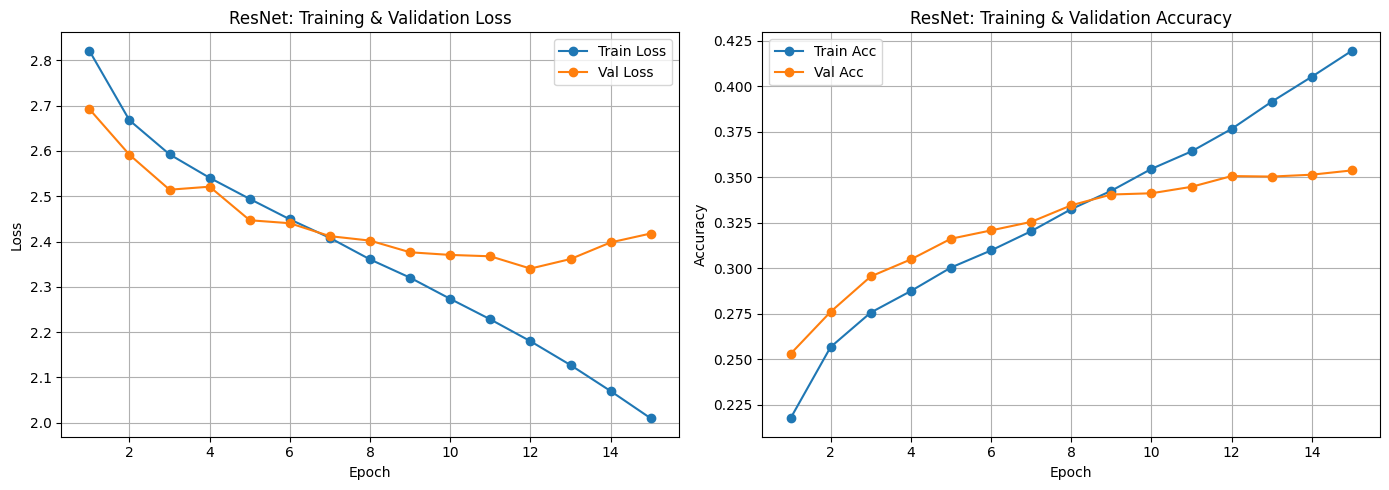

In [11]:
# Cell: Plot ResNet Training History
import matplotlib.pyplot as plt
import pickle

# Load history
with open('resnet_history.pkl', 'rb') as f:
    history_res = pickle.load(f)

epochs_range = range(1, len(history_res['train_loss']) + 1)

plt.figure(figsize=(14, 5))

# Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history_res['train_loss'], label='Train Loss', marker='o')
plt.plot(epochs_range, history_res['val_loss'], label='Val Loss', marker='o')
plt.title('ResNet: Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history_res['train_acc'], label='Train Acc', marker='o')
plt.plot(epochs_range, history_res['val_acc'], label='Val Acc', marker='o')
plt.title('ResNet: Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [15]:
# Cell: Load model and get predictions
import torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import label_binarize

import numpy as np
from sklearn.metrics import roc_curve, auc # Added roc_curve and auc imports

model_res = resnet101(weights=ResNet101_Weights.DEFAULT)
num_ftrs = model_res.fc.in_features
model_res.fc = nn.Linear(num_ftrs, num_classes)
model_res.load_state_dict(torch.load('resnet_best.pth'))
model_res.to(device)
model_res.eval()

def get_predictions_and_labels(model, dataloader):
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for inputs, labels in tqdm(dataloader):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            probs = F.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return np.array(all_preds), np.array(all_labels), np.array(all_probs)

res_preds, true_labels, res_probs = get_predictions_and_labels(model_res, test_dl)

  0%|          | 0/244 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
100%|██████████| 244/244 [02:28<00:00,  1.64it/s]


In [16]:
# Cell: Accuracy
res_acc = np.mean(res_preds == true_labels)
print(f"ResNet Test Accuracy: {res_acc:.4f}")

ResNet Test Accuracy: 0.3512


In [23]:
# Cell: Display Category ID to Category Name Mapping
# Assuming 'df' is your original filtered DataFrame with 'CATEGORY ID' and 'CATEGORY' columns
# Run this after loading the CSV (e.g., after Cell 3 in previous codes)

import pandas as pd

# If df is not in memory, reload it
csv_path = '/content/drive/MyDrive/book_list.csv'
df = pd.read_csv(csv_path, encoding='latin-1')

# Create mapping from CATEGORY ID to CATEGORY
category_mapping = df[['CATEGORY ID', 'CATEGORY']].drop_duplicates().sort_values('CATEGORY ID')
category_mapping = category_mapping.set_index('CATEGORY ID')['CATEGORY'].to_dict()

# Print the mapping
print("Category ID to Category Name Mapping:")
for cat_id, cat_name in category_mapping.items():
    print(f"ID {cat_id}: {cat_name}")

# Optional: Save to CSV for presentation
mapping_df = pd.DataFrame(list(category_mapping.items()), columns=['CATEGORY ID', 'CATEGORY'])
mapping_df.to_csv('category_mapping.csv', index=False)
print("\nMapping saved to 'category_mapping.csv'")

# Optional: Display as a table (for notebook)
display(mapping_df)

Category ID to Category Name Mapping:
ID 0: Arts & Photography
ID 1: Biographies & Memoirs
ID 2: Business & Money
ID 3: Calendars
ID 4: Children's Books
ID 5: Comics & Graphic Novels
ID 6: Computers & Technology
ID 7: Cookbooks, Food & Wine
ID 8: Crafts, Hobbies & Home
ID 9: Christian Books & Bibles
ID 10: Engineering & Transportation
ID 11: Health, Fitness & Dieting
ID 12: History
ID 13: Humor & Entertainment
ID 14: Law
ID 15: Literature & Fiction
ID 16: Medical Books
ID 17: Mystery, Thriller & Suspense
ID 18: Parenting & Relationships
ID 19: Politics & Social Sciences
ID 20: Reference
ID 21: Religion & Spirituality
ID 22: Romance
ID 23: Science & Math
ID 24: Science Fiction & Fantasy
ID 25: Self-Help
ID 26: Sports & Outdoors
ID 27: Teen & Young Adult
ID 28: Test Preparation
ID 29: Travel
ID 30: Gay & Lesbian
ID 31: Education & Teaching

Mapping saved to 'category_mapping.csv'


,CATEGORY ID,CATEGORY
0,0,Arts & Photography
1,1,Biographies & Memoirs
2,2,Business & Money
3,3,Calendars
4,4,Children's Books
5,5,Comics & Graphic Novels
6,6,Computers & Technology
7,7,"Cookbooks, Food & Wine"
8,8,"Crafts, Hobbies & Home"
9,9,Christian Books & Bibles


from matplotlib import pyplot as plt
mapping_df['CATEGORY ID'].plot(kind='hist', bins=20, title='CATEGORY ID')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
import seaborn as sns
def _plot_series(series, series_name, series_index=0):
  palette = list(sns.palettes.mpl_palette('Dark2'))
  counted = (series['CATEGORY ID']
                .value_counts()
              .reset_index(name='counts')
              .rename({'index': 'CATEGORY ID'}, axis=1)
              .sort_values('CATEGORY ID', ascending=True))
  xs = counted['CATEGORY ID']
  ys = counted['counts']
  plt.plot(xs, ys, label=series_name, color=palette[series_index % len(palette)])

fig, ax = plt.subplots(figsize=(10, 5.2), layout='constrained')
df_sorted = mapping_df.sort_values('CATEGORY ID', ascending=True)
_plot_series(df_sorted, '')
sns.despine(fig=fig, ax=ax)
plt.xlabel('CATEGORY ID')
_ = plt.ylabel('count()')

from matplotlib import pyplot as plt
mapping_df['CATEGORY ID'].plot(kind='line', figsize=(8, 4), title='CATEGORY ID')
plt.gca().spines[['top', 'right']].set_visible(False)

In [17]:
# Cell: Classification Report
report = classification_report(true_labels, res_preds, target_names=[str(i) for i in range(num_classes)], output_dict=True)
print(classification_report(true_labels, res_preds, target_names=[str(i) for i in range(num_classes)]))

              precision    recall  f1-score   support

           0       0.20      0.15      0.17       969
           1       0.19      0.23      0.21       639
           2       0.26      0.24      0.25      1494
           3       0.47      0.35      0.40       395
           4       0.47      0.65      0.55      2041
           5       0.52      0.49      0.51       454
           6       0.39      0.57      0.46      1197
           7       0.66      0.58      0.62      1320
           8       0.32      0.42      0.36      1490
           9       0.23      0.36      0.28      1371
          10       0.45      0.18      0.25       401
          11       0.31      0.27      0.28      1783
          12       0.26      0.23      0.24      1019
          13       0.21      0.17      0.19      1035
          14       0.37      0.31      0.34      1097
          15       0.24      0.17      0.20      1137
          16       0.40      0.42      0.41      1813
          17       0.32    

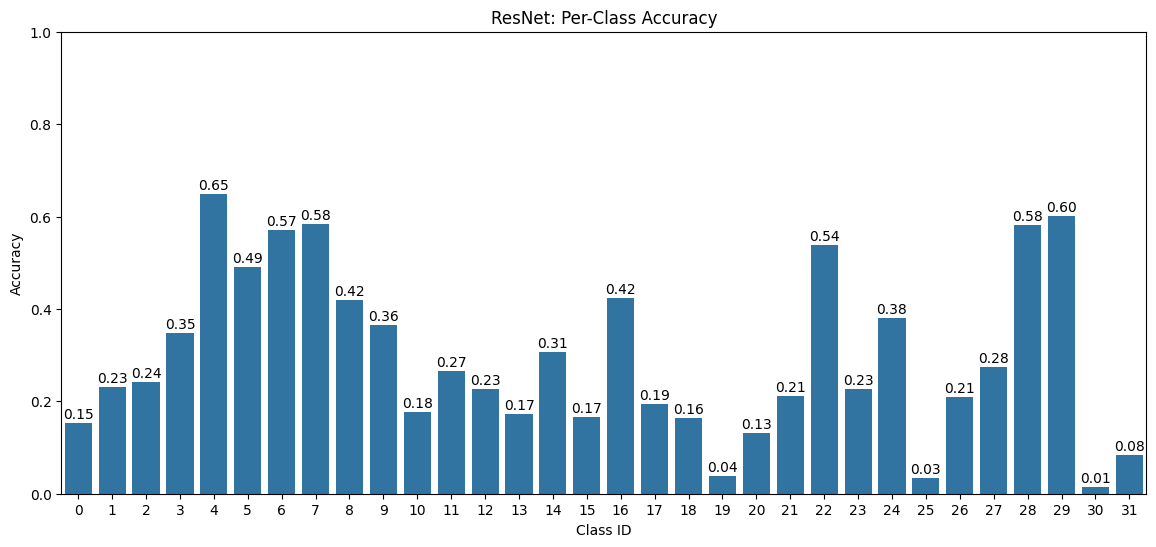

In [19]:
# Cell: Per-class Accuracy Bar Plot
import matplotlib.pyplot as plt
import seaborn as sns # Import seaborn

per_class_acc = [report[str(i)]['recall'] for i in range(num_classes)]
plt.figure(figsize=(14, 6))
sns.barplot(x=list(range(num_classes)), y=per_class_acc)
plt.title('ResNet: Per-Class Accuracy')
plt.xlabel('Class ID')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
for i, v in enumerate(per_class_acc):
    plt.text(i, v + 0.01, f'{v:.2f}', ha='center')
plt.show()

<Figure size 1200x1000 with 0 Axes>

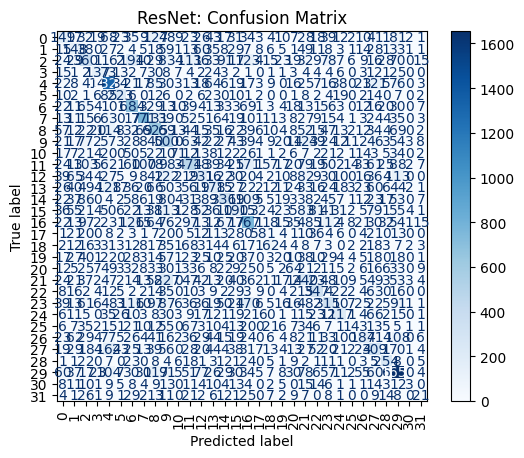

In [21]:
# Cell: Confusion Matrix
cm = confusion_matrix(true_labels, res_preds)
plt.figure(figsize=(12, 10))
ConfusionMatrixDisplay(cm, display_labels=list(range(num_classes))).plot(cmap='Blues', xticks_rotation='vertical')
plt.title('ResNet: Confusion Matrix')
plt.show()

Avg Precision: 0.3155, Recall: 0.2962, F1: 0.2971


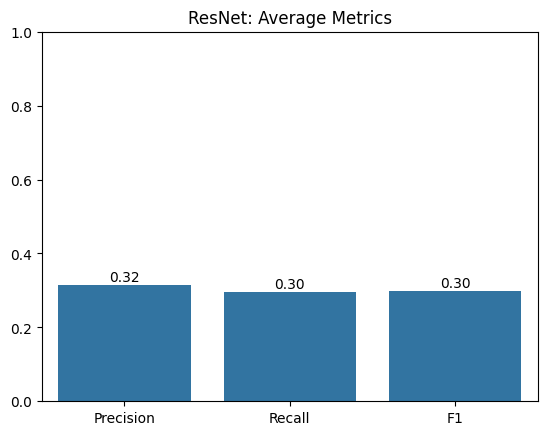

In [20]:
# Cell: Avg Precision, Recall, F1
import matplotlib.pyplot as plt
import seaborn as sns # Import seaborn
import numpy as np # Import numpy

precision = [report[str(i)]['precision'] for i in range(num_classes)]
recall = [report[str(i)]['recall'] for i in range(num_classes)]
f1 = [report[str(i)]['f1-score'] for i in range(num_classes)]

avg_prec = np.mean(precision)
avg_rec = np.mean(recall)
avg_f1 = np.mean(f1)

print(f"Avg Precision: {avg_prec:.4f}, Recall: {avg_rec:.4f}, F1: {avg_f1:.4f}")

metrics = ['Precision', 'Recall', 'F1']
values = [avg_prec, avg_rec, avg_f1]
sns.barplot(x=metrics, y=values)
plt.title('ResNet: Average Metrics')
plt.ylim(0, 1)
for i, v in enumerate(values):
    plt.text(i, v + 0.01, f'{v:.2f}', ha='center')
plt.show()

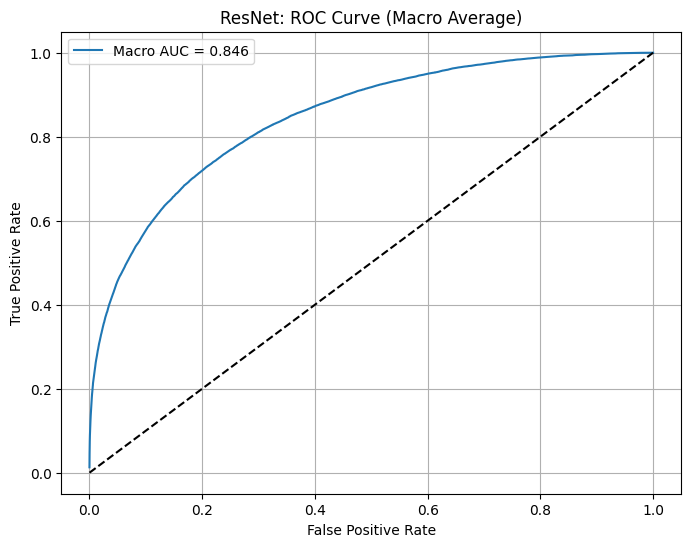

In [22]:
# Cell: Fixed ROC Curve (Macro Average) - Remove scipy.interp import and use np.interp
import numpy as np
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# Assuming res_probs, true_labels, num_classes are defined from previous cells
bin_labels = label_binarize(true_labels, classes=range(num_classes))

fpr, tpr, roc_auc = {}, {}, {}

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(bin_labels[:, i], res_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Macro average using np.interp (no scipy needed)
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(num_classes)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(num_classes):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])  # Fixed: uses np.interp
mean_tpr /= num_classes
fpr["macro"] = all_fpr
tpr["macro"] = mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot
plt.figure(figsize=(8, 6))
plt.plot(fpr["macro"], tpr["macro"], label=f'Macro AUC = {roc_auc["macro"]:.3f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ResNet: ROC Curve (Macro Average)')
plt.legend()
plt.grid()
plt.show()